In [20]:
import pandas as pd
import numpy as np
import duckdb 
import polars as pl

In [21]:
import re

In [22]:
import matplotlib.pyplot as plt

In [23]:
import seaborn as sns

- countries
- countries_en
- origins
- manufacturing_places
- categories
- fiber_100g
- proteins_100g
- salt_100g
- sodium_100g
- serving_size

In [24]:
path = 'Downloads/archive (1)/open_food_facts_2025 (1).csv'

In [25]:
df = pd.read_csv(path, usecols=['url','countries','countries_en','origins','manufacturing_places','categories','fiber_100g','proteins_100g','salt_100g','sodium_100g','serving_size'])   

In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1350091 entries, 0 to 1350090
Data columns (total 11 columns):
 #   Column                Non-Null Count    Dtype  
---  ------                --------------    -----  
 0   url                   1350091 non-null  str    
 1   countries             1347005 non-null  str    
 2   countries_en          1347005 non-null  str    
 3   origins               125550 non-null   str    
 4   manufacturing_places  159544 non-null   str    
 5   categories            1349037 non-null  str    
 6   fiber_100g            513072 non-null   float64
 7   proteins_100g         928103 non-null   float64
 8   salt_100g             928492 non-null   float64
 9   sodium_100g           928492 non-null   float64
 10  serving_size          617260 non-null   str    
dtypes: float64(4), str(7)
memory usage: 378.7 MB


In [27]:
# Missing Value Percentage
df.isnull().mean() * 100

url                      0.000000
countries                0.228577
countries_en             0.228577
origins                 90.700627
manufacturing_places    88.182722
categories               0.078069
fiber_100g              61.997228
proteins_100g           31.256263
salt_100g               31.227451
sodium_100g             31.227451
serving_size            54.280119
dtype: float64

Rishabh note
- countries and countries_en are the same fields only difference being that one is in English and the other is in the native language.
- we keep countries_en

- origin and manufacturing_places have too many missing records.
- In our project we only care about the ingredients of products themselves.
- So dropping these rows should be fine

- sodium is just a component of salt ( salt = sodium * 2.5). Keeping only one makes sense. I plan to cross-fill missing values and then keep only one of them (1 that has least missing values).


In [28]:
df["salt_100g"] = df["salt_100g"].fillna(df["sodium_100g"] * 2.5)
df["sodium_100g"] = df["sodium_100g"].fillna(df["salt_100g"] / 2.5)

In [29]:
df.isnull().sum()

url                           0
countries                  3086
countries_en               3086
origins                 1224541
manufacturing_places    1190547
categories                 1054
fiber_100g               837019
proteins_100g            421988
salt_100g                421599
sodium_100g              421599
serving_size             732831
dtype: int64

In [30]:
df = df.drop(columns=["sodium_100g","countries","origins","manufacturing_places"])

In [31]:
# A serving of 100g cannot have an ingredient more than 100g
df = df[
    (df["proteins_100g"].isna() | df["proteins_100g"].between(0, 100))
    & (df["fiber_100g"].isna() | df["fiber_100g"].between(0, 100))
    # & (df["salt_100g"].isna() | df["salt_100g"].between(0, 100))
]

In [32]:
df.head()

,url,countries_en,categories,fiber_100g,proteins_100g,salt_100g,serving_size
0,http://world-en.openfoodfacts.org/product/0000...,"Germany,Spain","Aliments et boissons à base de végétaux, Alime...",NaN,NaN,NaN,25 gram
1,http://world-en.openfoodfacts.org/product/0000...,"Germany,Spain","it:Gestione sovrappeso, it:obesità, Wrap",NaN,NaN,NaN,0g
2,http://world-en.openfoodfacts.org/product/0000...,Switzerland,"Snacks, Meals, Rice dishes, Risottos, Powder p...",NaN,NaN,NaN,0g
3,http://world-en.openfoodfacts.org/product/0000...,France,"Snacks, Snacks sucrés, Biscuits et gâteaux, Gâ...",NaN,NaN,NaN,"21,6g"
4,http://world-en.openfoodfacts.org/product/0000...,Brazil,"Snacks, Snacks sucrés, Biscuits et gâteaux, Gâ...",NaN,NaN,NaN,54g


In [33]:
df["categories"] = (
    df["categories"]
    .fillna("unknown")
    .astype(str)
    .str.lower()
    .str.replace("en:", "", regex=False)
    .str.split(",")
    .str[0]
    .str.strip()
)

In [34]:
df.head()

,url,countries_en,categories,fiber_100g,proteins_100g,salt_100g,serving_size
0,http://world-en.openfoodfacts.org/product/0000...,"Germany,Spain",aliments et boissons à base de végétaux,NaN,NaN,NaN,25 gram
1,http://world-en.openfoodfacts.org/product/0000...,"Germany,Spain",it:gestione sovrappeso,NaN,NaN,NaN,0g
2,http://world-en.openfoodfacts.org/product/0000...,Switzerland,snacks,NaN,NaN,NaN,0g
3,http://world-en.openfoodfacts.org/product/0000...,France,snacks,NaN,NaN,NaN,"21,6g"
4,http://world-en.openfoodfacts.org/product/0000...,Brazil,snacks,NaN,NaN,NaN,54g


In [35]:
df['serving_size'].value_counts()

serving_size
100g                   40238
1 ONZ (28 g)           16909
100 g                  15099
30 g                    8575
30g                     7596
                       ...  
2 tranches (67 g)          1
16 rings (28 g)            1
803.9999999999999g         1
1 kis pohár (150 g)        1
337.35905g                 1
Name: count, Length: 61567, dtype: int64

In [36]:
def extract_serving_grams(val):
  if pd.isna(val):
    return None
  val_str = str(val).lower()

  # 1. Priority: Look for numbers inside parentheses followed by 'g' (e.g., "(28 g)", "(67g)")
  paren_match = re.search(r"\(([0-9]+(?:\.[0-9]+)?)\s*g\)", val_str)
  if paren_match:
    return float(paren_match.group(1))

  # 2. Secondary: Look for standard weight patterns (e.g., "30g", "100 g", "803.99g")
  direct_match = re.search(r"([0-9]+(?:\.[0-9]+)?)\s*g", val_str)
  if direct_match:
    return float(direct_match.group(1))

  # 3. Fallback: Grab the first available number if no 'g' label is found
  fallback_match = re.search(r"([0-9]+(?:\.[0-9]+)?)", val_str)
  if fallback_match:
    return float(fallback_match.group(1))

  return None

In [37]:
# Apply the function to create a clean numeric column in grams
df["serving_size_g"] = df["serving_size"].apply(extract_serving_grams)

# Check the results
print(df[["serving_size", "serving_size_g"]].head(10))

  serving_size  serving_size_g
0      25 gram            25.0
1           0g             0.0
2           0g             0.0
3        21,6g             6.0
4          54g            54.0
5         10 g            10.0
6          11g            11.0
7           0g             0.0
8         14 g            14.0
9          NaN             NaN


In [38]:
df["countries_en"] = df["countries_en"].fillna("unknown").str.lower().str.strip()

In [39]:
# Groupby Imputation: if a product is missing its protein value, fill it with the median protein value of its specific food category
nutrient_cols = ["fiber_100g", "proteins_100g", "salt_100g"]

for col in nutrient_cols:
  # 1. Fill missing values with the median of their specific category
  df[col] = df[col].fillna(df.groupby("categories")[col].transform("median"))

  # 2. Fallback: If an entire category is missing/empty, fill with the global median
  df[col] = df[col].fillna(df[col].median())

In [40]:
# Fill with category median, then global median as a backup
df["serving_size_g"] = df["serving_size_g"].fillna(
    df.groupby("categories")["serving_size_g"].transform("median")
)
df["serving_size_g"] = df["serving_size_g"].fillna(
    df["serving_size_g"].median()
)

In [41]:
df = df.drop(columns=["serving_size"])

In [42]:
df.isnull().sum()

url               0
countries_en      0
categories        0
fiber_100g        0
proteins_100g     0
salt_100g         0
serving_size_g    0
dtype: int64

In [51]:
df.shape

(1349848, 7)

In [58]:
# View duplicate rows (excluding the first occurrence)
df[df.duplicated()]

,url,countries_en,categories,fiber_100g,proteins_100g,salt_100g,serving_size_g
746851,http://world-en.openfoodfacts.org/product/3760...,france,aliments et boissons à base de végétaux,2.5,2.2,0.05,100.0
746886,http://world-en.openfoodfacts.org/product/3760...,france,condiments,0.8,1.6,1.70,20.0
746919,http://world-en.openfoodfacts.org/product/3760...,france,snacks,2.7,6.2,0.39,30.0
1008938,http://world-en.openfoodfacts.org/product/6194...,"france,tunisia",aliments et boissons à base de végétaux,2.5,2.2,0.05,100.0


In [60]:
df.to_parquet('rgs.parquet')

# EDA

In [44]:
df.describe()

,fiber_100g,proteins_100g,salt_100g,serving_size_g
count,1.349848e+06,1.349848e+06,1.349848e+06,1.349848e+06
mean,2.102463e+00,7.941962e+00,1.263912e+00,4.043091e+25
std,3.212124e+00,7.593528e+00,8.585170e+01,4.697382e+28
min,0.000000e+00,0.000000e+00,-4.543632e-01,0.000000e+00
25%,4.073077e-02,2.500000e+00,1.000000e-01,3.000000e+01
50%,1.600000e+00,6.200000e+00,4.400000e-01,7.900000e+01
75%,2.700000e+00,1.023306e+01,1.172500e+00,1.000000e+02
max,1.000000e+02,1.000000e+02,9.250000e+04,5.457558e+31


In [45]:
print("Top 10 Food Categories")
top_categories = (
    df[df["categories"] != "unknown"]["categories"].value_counts().head(10)
)
print(top_categories)

Top 10 Food Categories
categories
snacks                                     180124
plant-based foods and beverages            126226
aliments et boissons à base de végétaux    120091
viandes et dérivés                          58073
condiments                                  50634
produits laitiers                           42812
dairies                                     38347
beverages                                   32624
undefined                                   32340
alimentos y bebidas de origen vegetal       28770
Name: count, dtype: int64


In [46]:
print("Top 10 Categories with Highest Average Protein")
avg_protein_cat = (
    df.groupby("categories")[["proteins_100g", "fiber_100g"]]
    .agg(mean_protein=("proteins_100g", "mean"), product_count=("proteins_100g", "count"))
    .query("product_count > 100")  # Filter for statistical significance
    .sort_values(by="mean_protein", ascending=False)
    .head(10)
)
print(avg_protein_cat)

Top 10 Categories with Highest Average Protein
                             mean_protein  product_count
categories                                              
protein-supplement              67.749310            120
saucisses sèches                28.624779            113
emmentaler                      27.968554            106
coppa                           27.125011            119
products for specific diets     27.103819            144
comte                           26.974931            121
es:fuet                         26.898933            356
edam                            25.030174            188
grated-cheese                   24.841815            160
italian meat products           24.736429            280


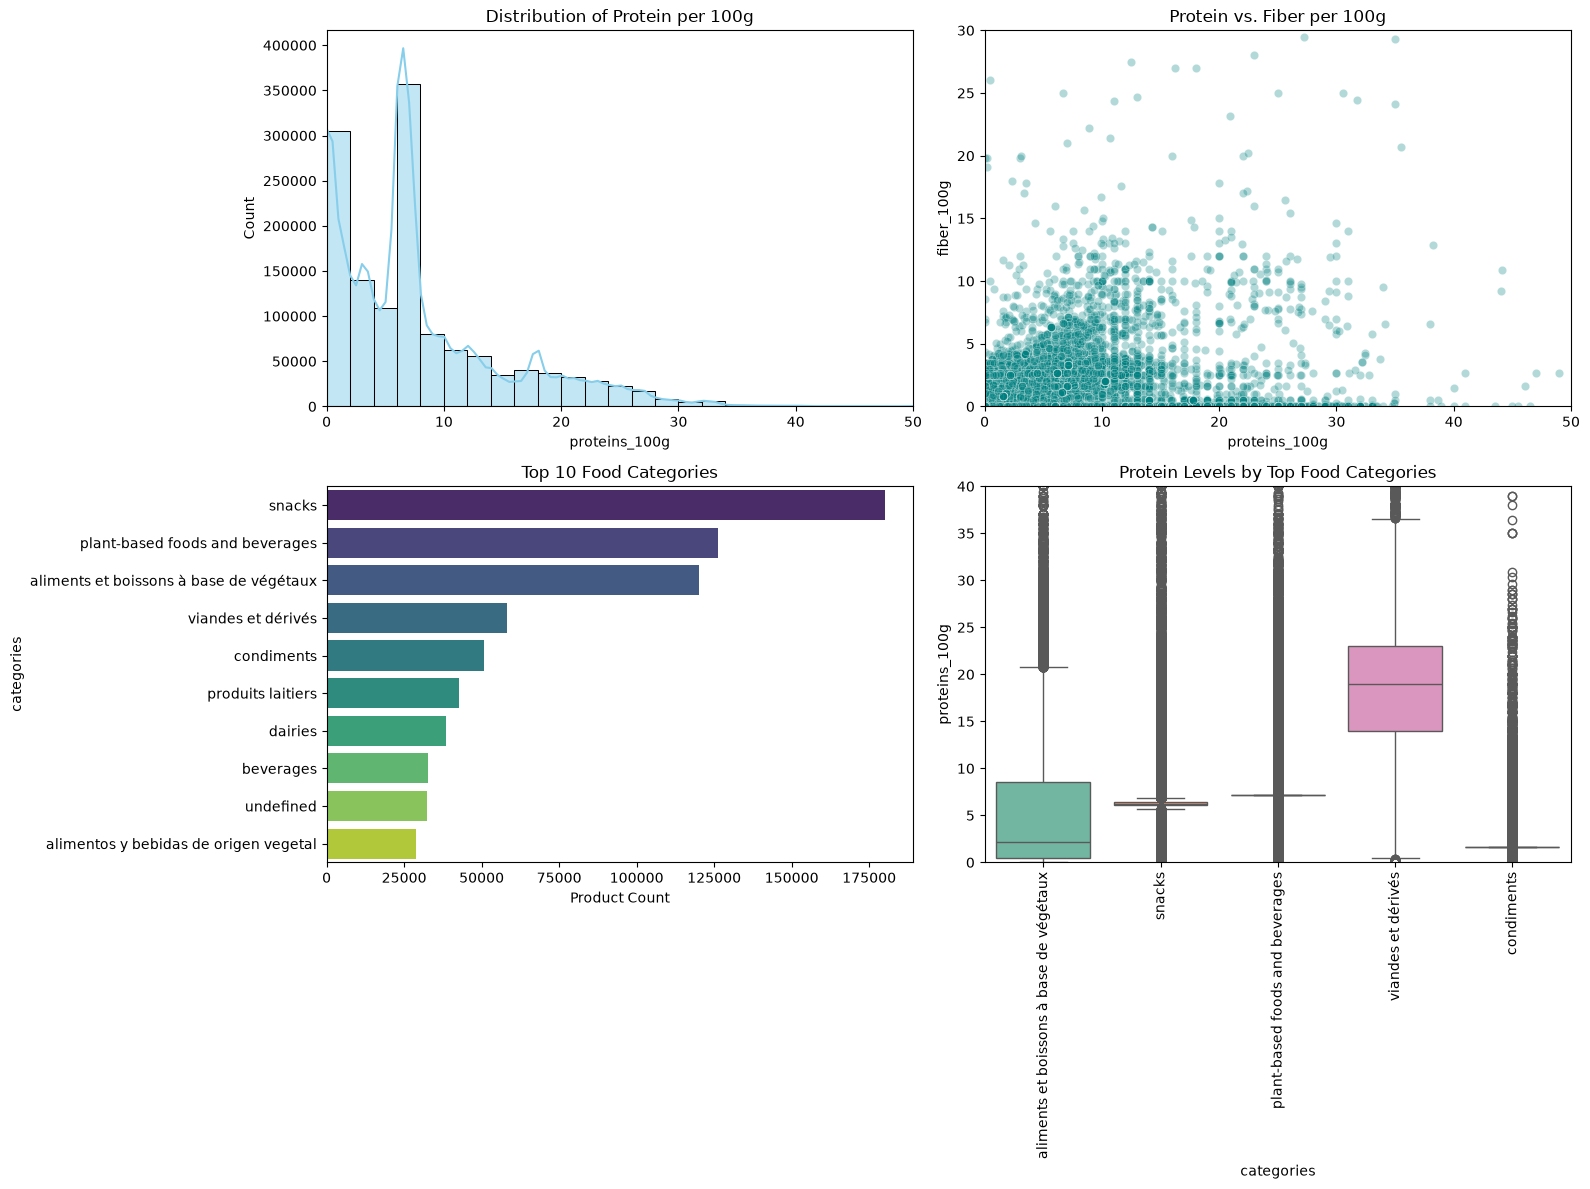

In [47]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot A: Distribution of Proteins per 100g (Histogram)
sns.histplot(
    df["proteins_100g"].dropna(),
    bins=50,
    kde=True,
    ax=axes[0, 0],
    color="skyblue",
)
axes[0, 0].set_title("Distribution of Protein per 100g")
axes[0, 0].set_xlim(0, 50)    # Zoom in on normal range (0-50g)
# Plot B: Protein vs. Fiber Scatter Plot (Sampled for performance)
sample_df = df.sample(min(10000, len(df)))
sns.scatterplot(
    data=sample_df,
    x="proteins_100g",
    y="fiber_100g",
    alpha=0.3,
    ax=axes[0, 1],
    color="teal",
)
axes[0, 1].set_title("Protein vs. Fiber per 100g")
axes[0, 1].set_xlim(0, 50)
axes[0, 1].set_ylim(0, 30)

# Plot C: Top 10 Categories Bar Chart
top_cats_plot = (
    df[df["categories"] != "unknown"]["categories"].value_counts().head(10)
)
sns.barplot(
    x=top_cats_plot.values,
    y=top_cats_plot.index,
    ax=axes[1, 0],
    palette="viridis",
    hue=top_cats_plot.index,
    legend=False,
)
axes[1, 0].set_title("Top 10 Food Categories")
axes[1, 0].set_xlabel("Product Count")

# Plot D: Protein Distribution Across Top 5 Categories (Boxplot)
top_5_cats = top_cats_plot.head(5).index.tolist()
box_data = df[df["categories"].isin(top_5_cats)]
sns.boxplot(
    data=box_data,
    x="categories",
    y="proteins_100g",
    ax=axes[1, 1],
    palette="Set2",
    hue="categories",
    legend=False,
)
axes[1, 1].set_title("Protein Levels by Top Food Categories")
axes[1, 1].tick_params(axis="x", rotation=90)
axes[1, 1].set_ylim(0, 40)

plt.tight_layout()
plt.show()

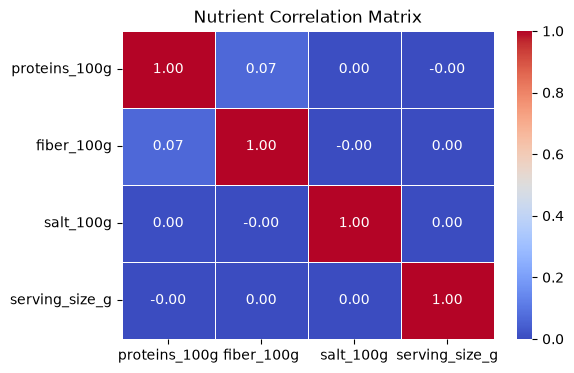

In [48]:
plt.figure(figsize=(6, 4))
corr = df[["proteins_100g", "fiber_100g", "salt_100g", "serving_size_g"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Nutrient Correlation Matrix")
plt.show()

In [50]:
df.shape

(1349848, 7)